# 01 · Tratamento — DATASUS

**Camada 2 do ETL — Tratamento.** Transforma as tabulações brutas (formato "largo" do TabNet,
tudo como texto) em tabelas **limpas, tipadas e em formato longo**, prontas para integração e
modelagem.

| | |
|---|---|
| **Entrada** | `data/01_leitura/datasus/*.parquet` |
| **Saída** | `data/02_tratamento/datasus/*.parquet` |
| **Próxima etapa** | `03_integracao_dengue_clima.ipynb` |

**Regras aplicadas**
1. `-` (zero no TabNet) → `0`; contagens viram inteiros.
2. Linhas e colunas `Total` são removidas (e usadas para conferência).
3. Rótulos `"110001 ALTA FLORESTA D'OESTE"` → `cod_municipio` (IBGE, 6 dígitos) + `nome_municipio`.
4. Casos sem município de residência ("MUNICIPIO IGNORADO", "Ignorado ou exterior") saem do painel
   municipal, mas são **quantificados** e guardados à parte.
5. Tabelas largas (semanas/anos/categorias nas colunas) → formato longo.
6. Categorias de "ignorado" padronizadas em um único rótulo: `Ignorado/Branco`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import epi  # noqa: E402
import viz  # noqa: E402
from config import ANO_FIM, ANO_INICIO, FIGURAS, LEITURA, TRATAMENTO, UF_POR_CODIGO  # noqa: E402

viz.aplicar_estilo()
ENTRADA = LEITURA / "datasus"
SAIDA = TRATAMENTO / "datasus"
SAIDA.mkdir(parents=True, exist_ok=True)
LINHAGEM = ["arquivo_origem", "coletado_em"]


def para_int(s: pd.Series) -> pd.Series:
    """'-' do TabNet significa zero."""
    return pd.to_numeric(s.replace("-", "0"), errors="raise").astype("int64")


def separar_codigo(rotulo: pd.Series, digitos: int) -> pd.DataFrame:
    """'110001 ALTA FLORESTA' -> ('110001', 'ALTA FLORESTA'). Sem código -> NaN."""
    return rotulo.str.extract(rf"^\s*(\d{{{digitos}}})\s+(.+?)\s*$").rename(columns={0: "codigo", 1: "nome"})

## 1. Núcleo: casos por município de residência × semana epidemiológica

In [2]:
bruto = pd.read_parquet(ENTRADA / "dengue_municipio_semana.parquet")
COL_MUN = "Município de residência"
semanas = [c for c in bruto.columns if c.startswith("Semana ")]
inesperadas = set(bruto.columns) - {COL_MUN, "Total", "ano_epi", *semanas, *LINHAGEM}
assert not inesperadas, f"colunas inesperadas: {inesperadas}"
print(f"{len(bruto):,} linhas brutas | {len(semanas)} colunas de semana".replace(",", "."))

# Conferência 1: soma das semanas == coluna Total, linha a linha
corpo = bruto[bruto[COL_MUN] != "Total"]
soma_semanas = corpo[semanas].replace("-", "0").fillna("0").astype(int).sum(axis=1)
assert (soma_semanas == para_int(corpo["Total"])).all()

longo = corpo.melt(id_vars=[COL_MUN, "ano_epi"], value_vars=semanas, var_name="semana", value_name="valor")
longo["ano_epi"] = longo["ano_epi"].astype(int)
longo["semana_epi"] = longo["semana"].str.extract(r"(\d+)")[0].astype(int)
longo["coluna_ausente"] = longo["valor"].isna()
longo["casos"] = para_int(longo["valor"].fillna("0"))
longo[["cod_municipio", "nome_municipio"]] = separar_codigo(longo[COL_MUN], 6).to_numpy()

# Regra para semanas ausentes no TabNet (coluna omitida = nenhum caso no país naquela semana):
#  * semana fora do calendário epidemiológico (ex.: 'Semana 53' em ano de 52 semanas) -> descartada;
#  * semanas futuras do ano corrente (após a última semana publicada)                -> descartadas (não observadas);
#  * demais                                                                           -> zero casos.
cal = epi.calendario(ANO_INICIO, ANO_FIM)
fora = longo.merge(cal[["ano_epi", "semana_epi"]], how="left", indicator=True).query("_merge == 'left_only'")
assert fora["casos"].sum() == 0, "há casos em semanas inexistentes no calendário"
longo = longo.merge(cal[["ano_epi", "semana_epi", "id_semana"]], on=["ano_epi", "semana_epi"])
ULTIMA_SEMANA = int(longo.loc[(longo.ano_epi == ANO_FIM) & ~longo.coluna_ausente, "semana_epi"].max())
futuras = (longo.ano_epi == ANO_FIM) & (longo.semana_epi > ULTIMA_SEMANA)
longo = longo[~futuras]
sem_caso = longo[longo.coluna_ausente].groupby("ano_epi")["semana_epi"].unique()
print(f"Última semana publicada: {ANO_FIM}/SE{ULTIMA_SEMANA:02d} (semanas seguintes de {ANO_FIM} descartadas).")
print("Semanas omitidas pelo TabNet por não terem casos (viram zero):", sem_caso.to_dict() or "nenhuma")

72.787 linhas brutas | 53 colunas de semana


Última semana publicada: 2026/SE44 (semanas seguintes de 2026 descartadas).
Semanas omitidas pelo TabNet por não terem casos (viram zero): nenhuma


### 1.1 Casos sem município de residência informado
Não podem entrar no painel municipal. Medimos quanto representam — se fosse muito, enviesaria a análise.

In [3]:
sem_mun = longo["cod_municipio"].isna() | (longo["cod_municipio"] == "000000")
ignorados = longo[sem_mun].copy()
ignorados["sigla_uf"] = ignorados[COL_MUN].str.extract(r"- ([A-Z]{2})$")[0].fillna("Exterior/ignorada")
ignorados = ignorados.groupby(["ano_epi", "sigla_uf"], as_index=False)["casos"].sum()
ignorados.to_parquet(SAIDA / "casos_sem_municipio.parquet", index=False)

total_ano = longo.groupby("ano_epi")["casos"].sum()
pct = (ignorados.groupby("ano_epi")["casos"].sum() / total_ano * 100).round(3)
print(f"Casos sem município: {viz.fmt_br(ignorados.casos.sum())} de {viz.fmt_br(total_ano.sum())} "
      f"({viz.fmt_br(ignorados.casos.sum() / total_ano.sum() * 100, 3)}%) — impacto desprezível.")
pct.rename("% sem município").to_frame().T

Casos sem município: 1.459 de 18.934.818 (0,008%) — impacto desprezível.


ano_epi,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% sem município,0.014,0.018,0.047,0.003,0.007,0.003,0.003,0.013,0.014,0.001,0.0,0.001,0.002


In [4]:
dengue_semana = (longo[~sem_mun][["cod_municipio", "id_semana", "ano_epi", "semana_epi", "casos"]]
                 .astype({"casos": "int32", "ano_epi": "int16", "semana_epi": "int8"})
                 .sort_values(["cod_municipio", "id_semana"]).reset_index(drop=True))
dengue_semana.to_parquet(SAIDA / "dengue_municipio_semana.parquet", index=False)
print(f"{dengue_semana.cod_municipio.nunique():,} municípios × {dengue_semana.id_semana.nunique()} semanas "
      f"= {len(dengue_semana):,} linhas | {dengue_semana.casos.sum():,} casos".replace(",", "."))
dengue_semana.head()

5.571 municípios × 671 semanas = 3.738.141 linhas | 18.933.359 casos


,cod_municipio,id_semana,ano_epi,semana_epi,casos
0,110001,201401,2014,1,0
1,110001,201402,2014,2,0
2,110001,201403,2014,3,1
3,110001,201404,2014,4,0
4,110001,201405,2014,5,1


## 2. População residente (denominador da incidência)

Estimativas SVS/IBGE por município, 2014–2025. **2026 ainda não foi publicado**: repetimos a
população de 2025 e marcamos a linha com `populacao_repetida = True`.

In [5]:
pop_bruta = pd.read_parquet(ENTRADA / "populacao__populacao_municipio_x_ano.parquet").drop(columns=LINHAGEM)
pop_bruta = pop_bruta[pop_bruta["Município"] != "Total"]
pop = pop_bruta.melt(id_vars="Município", var_name="ano", value_name="populacao")
pop[["cod_municipio", "nome_municipio"]] = separar_codigo(pop["Município"], 6).to_numpy()
pop = pop.dropna(subset=["cod_municipio"])
pop["ano"] = pop["ano"].astype(int)
pop["populacao"] = para_int(pop["populacao"])
# População 0 = município ainda não instalado naquele ano -> ausente (evita divisão por zero na incidência)
criados = pop.loc[pop["populacao"] == 0].groupby("cod_municipio")["ano"].max()
pop["populacao"] = pop["populacao"].astype("Int64").mask(pop["populacao"] == 0)
print("Municípios instalados durante o período (população ausente antes da instalação):",
      {c: f"até {a}" for c, a in criados.items()})
pop["populacao_repetida"] = False
ultimo = pop["ano"].max()
extra = [pop[pop.ano == ultimo].assign(ano=a, populacao_repetida=True) for a in range(ultimo + 1, ANO_FIM + 1)]
pop = pd.concat([pop, *extra], ignore_index=True)[["cod_municipio", "ano", "populacao", "populacao_repetida"]]
pop.to_parquet(SAIDA / "populacao_municipio_ano.parquet", index=False)

sem_pop = set(dengue_semana.cod_municipio) - set(pop.cod_municipio)
print(f"População para {pop.cod_municipio.nunique():,} municípios, anos {pop.ano.min()}–{pop.ano.max()}. "
      f"Municípios do SINAN sem população: {len(sem_pop)} {sorted(sem_pop)}".replace(",", "."))
pop.groupby("ano")["populacao"].sum().rename("Brasil").to_frame().T

Municípios instalados durante o período (população ausente antes da instalação): {'510183': 'até 2024'}


População para 5.571 municípios. anos 2014–2026. Municípios do SINAN sem população: 0 []


ano,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Brasil,200811131,202403642,203871925,205211557,206529038,207900099,209164889,210103642,210862983,211695158,212583750,213421037,213421037


## 3. Cadastro de municípios

Atributos territoriais vindos das próprias tabulações: UF/região (pelo código IBGE), capital
(tabulação por capital) e **município em extrema pobreza** (filtro do TabNet).

> Limitação: o atributo "extrema pobreza" foi obtido filtrando casos de dengue, então só aparecem
> municípios dessa categoria com ao menos um caso em 2014–2026. Como quase todo município teve casos
> no período, a perda é pequena — mas é registrada.

In [6]:
capitais = pd.read_parquet(ENTRADA / "contexto__capital_residencia_x_ano.parquet")
cod_capitais = set(separar_codigo(capitais["Capital de residência"], 6)["codigo"].dropna())
pobreza = pd.read_parquet(ENTRADA / "desigualdade__municipios_extrema_pobreza_x_ano.parquet")
cod_pobreza = set(separar_codigo(pobreza["Município de residência"], 6)["codigo"].dropna()) - {"000000"}

municipios = (longo[~sem_mun][["cod_municipio", "nome_municipio"]].drop_duplicates("cod_municipio")
              .sort_values("cod_municipio").reset_index(drop=True))
uf = municipios["cod_municipio"].str[:2].map(UF_POR_CODIGO)
municipios["cod_uf"] = municipios["cod_municipio"].str[:2]
municipios["sigla_uf"] = uf.str[0]
municipios["nome_uf"] = uf.str[1]
municipios["regiao"] = uf.str[2]
municipios["capital"] = municipios["cod_municipio"].isin(cod_capitais)
municipios["extrema_pobreza"] = municipios["cod_municipio"].isin(cod_pobreza)
municipios = municipios.merge(pop[pop.ano == ultimo][["cod_municipio", "populacao"]]
                              .rename(columns={"populacao": f"populacao_{ultimo}"}), how="left")
assert municipios["sigla_uf"].notna().all()
municipios.to_parquet(SAIDA / "municipios.parquet", index=False)
print(f"{len(municipios):,} municípios | {municipios.capital.sum()} capitais | "
      f"{municipios.extrema_pobreza.sum():,} em extrema pobreza".replace(",", "."))
municipios.groupby("regiao").agg(municipios=("cod_municipio", "size"), capitais=("capital", "sum"),
                                  extrema_pobreza=("extrema_pobreza", "sum"))

5.571 municípios | 27 capitais | 1.580 em extrema pobreza


,municipios,capitais,extrema_pobreza
regiao,,,
Centro-Oeste,468,4,73
Nordeste,1794,9,936
Norte,450,7,171
Sudeste,1668,4,236
Sul,1191,3,164


## 4. Contexto anual (UF, região, semana nacional) e conferência cruzada

In [7]:
def anual_longo(arquivo: str, col: str, digitos: int | None) -> pd.DataFrame:
    df = pd.read_parquet(ENTRADA / arquivo).drop(columns=LINHAGEM)
    df = df[df[col] != "Total"].drop(columns="Total")
    lg = df.melt(id_vars=col, var_name="ano", value_name="casos")
    lg["ano"] = lg["ano"].astype(int)
    lg["casos"] = para_int(lg["casos"])
    if digitos:
        lg[["codigo", "nome"]] = separar_codigo(lg[col], digitos).to_numpy()
    return lg


uf_ano = anual_longo("contexto__uf_residencia_x_ano.parquet", "UF de residência", 2)
uf_ano = uf_ano.rename(columns={"codigo": "cod_uf", "nome": "nome_uf"})[["cod_uf", "nome_uf", "ano", "casos"]]
uf_ano.to_parquet(SAIDA / "contexto_uf_ano.parquet", index=False)

regiao_ano = anual_longo("contexto__regiao_residencia_x_ano.parquet", "Região de residência", 1)
regiao_ano["regiao"] = regiao_ano["nome"].str.replace("Região ", "", regex=False)
regiao_ano[["regiao", "ano", "casos"]].to_parquet(SAIDA / "contexto_regiao_ano.parquet", index=False)

semana_ano = anual_longo("contexto__semana_epidemiologica_x_ano.parquet", "Semana epidem. 1º Sintomas(s)", None)
semana_ano["semana_epi"] = semana_ano["Semana epidem. 1º Sintomas(s)"].str.extract(r"(\d+)").astype(int)
semana_ano = semana_ano.rename(columns={"ano": "ano_epi"})[["ano_epi", "semana_epi", "casos"]]
semana_ano.to_parquet(SAIDA / "contexto_semana_brasil.parquet", index=False)

# Conferência cruzada: painel municipal (+ ignorados da UF) vs tabulação direta por UF
painel_uf = (longo.assign(cod_uf=longo["cod_municipio"].str[:2])
             .assign(cod_uf=lambda d: d["cod_uf"].where(~sem_mun, d[COL_MUN].str.extract(r"- ([A-Z]{2})$")[0]
                                                            .map({v[0]: k for k, v in UF_POR_CODIGO.items()})))
             .groupby(["cod_uf", "ano_epi"])["casos"].sum().rename("painel"))
painel_uf.index = painel_uf.index.set_names(["cod_uf", "ano"])
confere = (uf_ano[uf_ano.cod_uf != "00"].set_index(["cod_uf", "ano"])["casos"].rename("tabnet_uf").to_frame()
           .join(painel_uf, how="left").fillna(0))
confere = confere[confere.index.get_level_values("ano") <= ANO_FIM]
dif = (confere["tabnet_uf"] - confere["painel"]).abs()
print(f"UF×ano conferidos: {len(confere)} | diferença absoluta total: {int(dif.sum())} casos "
      f"({viz.fmt_br(dif.sum() / confere['tabnet_uf'].sum() * 100, 4)}%) — tabulações independentes batem.")

UF×ano conferidos: 351 | diferença absoluta total: 11 casos (0,0001%) — tabulações independentes batem.


## 5. Perfil e gravidade (formato longo + categorias padronizadas)

In [8]:
IGNORADO = "Ignorado/Branco"
PADRONIZA = {"Ign/Branco": IGNORADO, "Em Branco": IGNORADO, "Ignorado": IGNORADO, "Em branco/IGN": IGNORADO,
             "Indigena": "Indígena", "Óbito pelo agravo notificado": "Óbito por dengue"}
ORDEM = {
    "Faixa etária": ["<1 Ano", "1-4", "5-9", "10-14", "15-19", "20-39", "40-59", "60-64", "65-69", "70-79", "80 e +", IGNORADO],
    "Sexo": ["Feminino", "Masculino", IGNORADO],
    "Raça/cor": ["Branca", "Preta", "Parda", "Amarela", "Indígena", IGNORADO],
    "Classificação final": ["Dengue", "Dengue com sinais de alarme", "Dengue grave", "Inconclusivo", IGNORADO],
    "Evolução": ["Cura", "Óbito por dengue", "Óbito por outra causa", "Óbito em investigação", IGNORADO],
    "Hospitalização": ["Sim", "Não", IGNORADO],
    "Sorotipo": ["DEN 1", "DEN 2", "DEN 3", "DEN 4", IGNORADO],
}
ARQUIVOS_PERFIL = {"Faixa etária": "faixa_etaria", "Sexo": "sexo", "Raça/cor": "raca",
                   "Classificação final": "class_final", "Evolução": "evolucao",
                   "Hospitalização": "ocorreu_hospitalizacao", "Sorotipo": "sorotipo"}


def perfil_longo(arquivo: str, dimensao: str, id_col: str) -> pd.DataFrame:
    df = pd.read_parquet(ENTRADA / arquivo).drop(columns=LINHAGEM)
    col0 = df.columns[0]
    df = df[df[col0] != "Total"].drop(columns="Total")
    lg = df.melt(id_vars=col0, var_name="categoria", value_name="casos").rename(columns={col0: id_col})
    lg["casos"] = para_int(lg["casos"])
    lg["categoria"] = lg["categoria"].replace(PADRONIZA)
    lg = lg.groupby([id_col, "categoria"], as_index=False)["casos"].sum()  # soma 'Em Branco' + 'Ignorado'
    faltando = set(lg["categoria"]) - set(ORDEM[dimensao])
    assert not faltando, f"{dimensao}: categorias sem ordem definida {faltando}"
    lg["ordem"] = lg["categoria"].map({c: i for i, c in enumerate(ORDEM[dimensao], 1)})
    return lg.assign(dimensao=dimensao)


perfil = pd.concat([perfil_longo(f"perfil__ano_x_{arq}.parquet", dim, "ano") for dim, arq in ARQUIVOS_PERFIL.items()],
                   ignore_index=True)
perfil["ano"] = perfil["ano"].astype(int)
perfil = perfil[["ano", "dimensao", "categoria", "ordem", "casos"]].sort_values(["dimensao", "ano", "ordem"])
perfil.to_parquet(SAIDA / "perfil_anual.parquet", index=False)

# Faixa etária × evolução e × hospitalização (2014–2026 acumulado)
fe_evo = perfil_longo("perfil__faixa_etaria_x_evolucao.parquet", "Evolução", "faixa_etaria")
fe_hosp = perfil_longo("perfil__faixa_etaria_x_ocorreu_hospitalizacao.parquet", "Hospitalização", "faixa_etaria")
gravidade = pd.concat([fe_evo, fe_hosp], ignore_index=True)
gravidade["faixa_etaria"] = gravidade["faixa_etaria"].replace(PADRONIZA)
gravidade["ordem_faixa"] = gravidade["faixa_etaria"].map({c: i for i, c in enumerate(ORDEM["Faixa etária"], 1)})
gravidade = gravidade[["faixa_etaria", "ordem_faixa", "dimensao", "categoria", "ordem", "casos"]]
gravidade.to_parquet(SAIDA / "gravidade_faixa_etaria.parquet", index=False)

totais = perfil.groupby("dimensao")["casos"].sum()
print("Total de casos por dimensão (deve ser ~igual em todas):")
print(totais.map(lambda v: f"{v:,}".replace(",", ".")).to_string())

Total de casos por dimensão (deve ser ~igual em todas):
dimensao
Classificação final    18.934.830
Evolução               18.934.830
Faixa etária           18.931.654
Hospitalização         18.934.830
Raça/cor               18.934.830
Sexo                   18.934.830
Sorotipo               18.934.830


> A tabulação por **faixa etária** soma 3.176 casos a menos (0,02%) que as demais: registros com
> idade fora das faixas do TabNet. Impacto desprezível, mas documentado.

### 5.1 Qualidade do preenchimento
Percentual de `Ignorado/Branco` por variável. É um dado importante para o **uso responsável**:
variáveis muito incompletas (como sorotipo e raça/cor) exigem cautela nas conclusões.

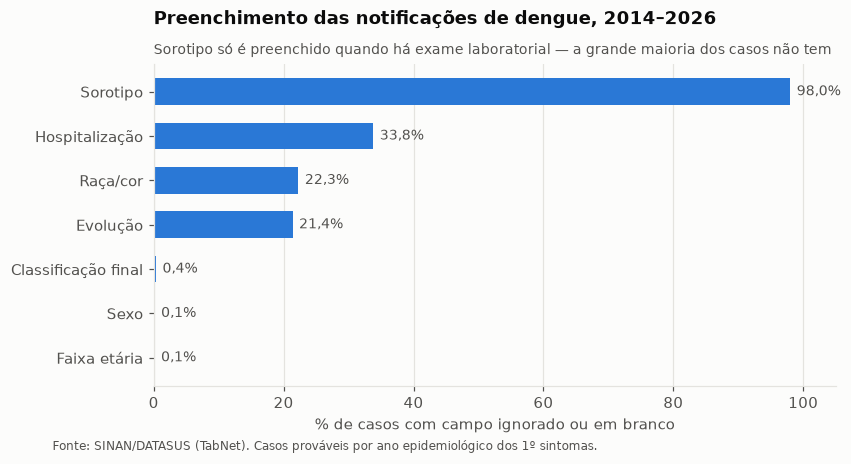

In [9]:
qualidade = (perfil.assign(ign=perfil["categoria"].eq(IGNORADO) * perfil["casos"])
             .groupby("dimensao")[["ign", "casos"]].sum())
qualidade["pct_ignorado"] = qualidade["ign"] / qualidade["casos"] * 100
qualidade = qualidade.sort_values("pct_ignorado")
qualidade.reset_index().to_parquet(SAIDA / "qualidade_preenchimento.parquet", index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(qualidade.index, qualidade["pct_ignorado"], color=viz.AZUL, height=0.6)
for y, v in enumerate(qualidade["pct_ignorado"]):
    ax.text(v + 1, y, f"{v:.1f}%".replace(".", ","), va="center", fontsize=9, color=viz.TEXTO_2)
ax.set_xlim(0, 105)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("% de casos com campo ignorado ou em branco")
ax.set_title("Preenchimento das notificações de dengue, 2014–2026")
viz.subtitulo(ax, "Sorotipo só é preenchido quando há exame laboratorial — a grande maioria dos casos não tem")
viz.fonte(fig, "Fonte: SINAN/DATASUS (TabNet). Casos prováveis por ano epidemiológico dos 1º sintomas.")
viz.salvar(fig, "tratamento_qualidade_preenchimento", FIGURAS)
plt.show()

## 6. Resumo das saídas

In [10]:
pd.DataFrame([(f.name, len(pd.read_parquet(f))) for f in sorted(SAIDA.glob("*.parquet"))],
             columns=["arquivo", "linhas"])

,arquivo,linhas
0,casos_sem_municipio.parquet,351
1,contexto_regiao_ano.parquet,78
2,contexto_semana_brasil.parquet,689
3,contexto_uf_ano.parquet,364
4,dengue_municipio_semana.parquet,3738141
5,gravidade_faixa_etaria.parquet,96
6,municipios.parquet,5571
7,perfil_anual.parquet,507
8,populacao_municipio_ano.parquet,72423
9,qualidade_preenchimento.parquet,7


Próximo passo: **`02_tratamento_inmet.ipynb`** (limpeza e agregação do clima) e depois
**`03_integracao_dengue_clima.ipynb`**.